# Amazon 5-core: разные товарные разделы


In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
import random
import json
import platform
import importlib.metadata
from pathlib import Path
from itertools import product
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from data_utils import (SEED, DATASET, REVISION, FILES, CATEGORIES, DATA_DIRECTORY,
                        MAX_ITEMS, MAX_USERS, local_data_ready, download_plan, download_data,
                        load_reviews, temporal_cutoffs, prepare_sample, load_metadata,
                        interaction_matrix, file_hash)
from evaluation import (make_relevance, evaluate, fit_model, search, paired_interval)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
thread_limiter = threadpool_limits(limits=1)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .2, "font.size": 10})
ARTIFACTS = Path("artifacts/amazon_5core")
ARTIFACTS.mkdir(parents=True, exist_ok=True)
versions = {name: importlib.metadata.version(name) for name in
            ["numpy", "scipy", "pandas", "matplotlib", "torch", "datasets", "huggingface-hub", "pyarrow"]}
print("Python:", platform.python_version(), "| seed:", SEED, "| device: CPU")
display(pd.Series(versions, name="version").to_frame())


Python: 3.13.5 | seed: 42 | device: CPU


,version
numpy,2.2.6
scipy,1.15.3
pandas,2.2.3
matplotlib,3.10.3
torch,2.6.0
datasets,3.6.0
huggingface-hub,0.33.0
pyarrow,20.0.0


## 1. Данные
[Amazon Reviews 2023](https://amazon-reviews-2023.github.io/), [5-core](https://amazon-reviews-2023.github.io/data_processing/5core.html): косметика и уход, творчество и шитьё, музыкальные инструменты, промышленные и научные товары.

Рекомендуем товары (`parent_asin`) пользователям (`user_id`). Событие — отзыв: оценка 1–5 и `timestamp` в мс. Релевантность — будущая оценка ≥4. Метаданные: название, раздел, путь категории, store. ID общие для всех разделов.

5-core оставляет пользователей и товары с ≥5 взаимодействиями в исходном разделе. Фильтрация выполнена авторами по всей истории, выбран этот вариант, так как скачивание абсолютно всех данных слишком затратно, а проверить хотелось на нескольких категориях. 


### Загрузка

Надо будет ввести токен с HF


In [ ]:
from getpass import getpass

if local_data_ready(DATA_DIRECTORY):
    print("Исходные файлы уже скачаны; сеть и токен не нужны.")
else:
    _hf_token = getpass("HF read token: ").strip() or False
    try:
        plan = download_plan(token=_hf_token, max_gb=5.0)
        display(plan[["file", "GB"]])
        print(f"Всего исходных файлов: {plan.GB.sum():.3f} ГБ")
        download_data(plan, token=_hf_token, directory=DATA_DIRECTORY)
    finally:
        _hf_token = None
        del _hf_token


Исходные файлы уже скачаны; сеть и токен не нужны.


In [ ]:
raw, clean, audit = load_reviews(DATA_DIRECTORY)
print("Набор:", DATASET, "| revision:", REVISION)
display(pd.Series({k: v for k, v in audit.items() if k != "missing"}, name="value").to_frame())
display(pd.Series(audit["missing"], name="missing_values").to_frame())
display(clean.head())

TRAIN_END, VALID_END = temporal_cutoffs(clean)
display(pd.DataFrame({"boundary": ["train / validation (q80)", "validation / test (q90)"],
                      "UTC": pd.to_datetime([TRAIN_END, VALID_END], unit="ms", utc=True)}))


user_sets = {d: set(raw.loc[raw.domain == d, "user_id"].unique()) for d in CATEGORIES}
user_overlap = pd.DataFrame({a: {b: len(user_sets[a] & user_sets[b]) for b in CATEGORIES}
                             for a in CATEGORIES})
print("Пересечения исходных user_id (диагональ — всего пользователей раздела):")
display(user_overlap)
del user_sets


Набор: McAuley-Lab/Amazon-Reviews-2023 | revision: 2b6d039ed471f2ba5fd2acb718bf33b0a7e5598e
Пересечения исходных user_id (диагональ — всего пользователей раздела):


,value
source_rows,9335661
source_users,961723
source_items,348042
source_domains,4
exact_duplicates,0
pair_duplicates,0
clean_rows,9335661
dropped_rows,0
users_in_multiple_domains,66161


,missing_values
user_id,0
parent_asin,0
rating,0
timestamp,0
domain,0


,user_id,parent_asin,rating,timestamp,domain
0,AGWDYYVVWM3DC3CASUZKXK67G6IA,B000050FET,5.0,977274582000,Beauty_and_Personal_Care
1,AG56LLVJV7SCRCBLLLFLQ3T2ANMA,B00002240R,4.0,994249707000,Industrial_and_Scientific
2,AH3HNM64SJKHC5R7IIKVXEYU227A,0806929987,5.0,1001897740000,Arts_Crafts_and_Sewing
3,AF7XARQBDONQLJGCU4HEF2PUWO2Q,0848724526,3.0,1011898704000,Arts_Crafts_and_Sewing
4,AE5HIDBRGIGGQADN247V5AID6KSQ,B01DZF81P2,4.0,1020909887000,Industrial_and_Scientific


,boundary,UTC
0,train / validation (q80),2022-02-08 18:05:17.199000+00:00
1,validation / test (q90),2022-10-17 23:06:08.989000+00:00


,Beauty_and_Personal_Care,Arts_Crafts_and_Sewing,Musical_Instruments,Industrial_and_Scientific
Beauty_and_Personal_Care,729576,49201,6172,11810
Arts_Crafts_and_Sewing,49201,197286,2977,8476
Musical_Instruments,6172,2977,57439,3138
Industrial_and_Scientific,11810,8476,3138,50985


## 2. EDA и выборка
Удаляем некорректные строки и повторные пары, сохраняя первое событие. Для товара фиксируем первый наблюдаемый раздел.

Отбор только по train: до 1500 популярных товаров на раздел с ≥2 положительными пользователями за последние 730 дней; при отсутствии недавних событий — весь train. До 30 000 недавно активных пользователей с ≥3 положительными товарами. Половину бюджета резервируем по разделам, остаток заполняем случайно (seed=42). Сохраняем историю внутри выбранных пользователей и каталога. Такой отбор поддерживает небольшие разделы, но смещает выборку к активной аудитории и популярным товарам.


In [ ]:
sample, train, valid, test, user_ids, item_ids, shape = prepare_sample(clean, TRAIN_END, VALID_END)
metadata, metadata_codes, source_metadata_rows = load_metadata(item_ids, DATA_DIRECTORY,
    sample.drop_duplicates("parent_asin").set_index("parent_asin").domain.to_dict())
X_train = interaction_matrix(train, shape)
seen_train = interaction_matrix(train, shape, positive_only=False)

stages = pd.DataFrame([
    ["Source CSVs (5-core)", len(raw), raw.user_id.nunique(), raw.parent_asin.nunique()],
    ["After cleaning", len(clean), clean.user_id.nunique(), clean.parent_asin.nunique()],
    ["Selected sample", len(sample), shape[0], shape[1]],
    ["Train", len(train), train.user_idx.nunique(), train.item_idx.nunique()],
    ["Validation", len(valid), valid.user_idx.nunique(), valid.item_idx.nunique()],
    ["Test", len(test), test.user_idx.nunique(), test.item_idx.nunique()],
], columns=["stage", "interactions", "users", "items"])
display(stages)
print(f"Train sparsity (all ratings): {1 - seen_train.nnz / np.prod(shape):.6%}")
print(f"Train sparsity (rating >=4): {1 - X_train.nnz / np.prod(shape):.6%}")
print("Прочитано строк метаданных:", source_metadata_rows)
display(pd.DataFrame({"missing_title": [metadata.title.eq("").sum()],
                      "missing_store": [metadata.store.eq("<missing>").sum()],
                      "missing_category": [metadata.category.str.endswith(" > <missing>").sum()],
                      "store_values": [metadata.store.nunique()],
                      "category_values": [metadata.category.nunique()]}))
print("После объединения редких значений: domain/category/store", metadata_codes.max(axis=0) + 1)

split_labels = np.select([sample.timestamp < TRAIN_END, sample.timestamp < VALID_END],
                         ["Train", "Validation"], default="Test")
print("События по разделам:")
display(pd.crosstab(sample.domain, split_labels))
train_domains = train[train.rating >= 4].groupby("user_idx").domain.nunique()
print("Пользователей с положительной историей в >=2 разделах train:", int((train_domains >= 2).sum()))

assert sample.groupby("user_id").user_idx.nunique().max() == 1

assert 100_000 <= len(sample) <= 2_000_000 and min(shape) >= 1000
assert len(sample) == len(train) + len(valid) + len(test)
assert not sample.duplicated(["user_id", "parent_asin"]).any()
assert train.timestamp.max() < valid.timestamp.min() <= valid.timestamp.max() < test.timestamp.min()
assert set(train.user_idx) == set(range(shape[0]))
assert set(train.item_idx) == set(range(shape[1]))
assert np.array_equal(metadata.parent_asin.to_numpy(), item_ids)
assert set(metadata.domain) == set(CATEGORIES)
assert metadata_codes.shape == (shape[1], 3) and (metadata_codes >= 0).all()
assert np.diff(X_train.indptr).min() >= 3
print("Sanity checks: объём, ID, пары, хронология, warm-start, метаданные — OK")


Train sparsity (all ratings): 99.911875%
Train sparsity (rating >=4): 99.920204%
Прочитано строк метаданных: 2471517
После объединения редких значений: domain/category/store [  4 322 229]
События по разделам:
Пользователей с положительной историей в >=2 разделах train: 7128
Sanity checks: объём, ID, пары, хронология, warm-start, метаданные — OK


,stage,interactions,users,items
0,Source CSVs (5-core),9335661,961723,348042
1,After cleaning,9335661,961723,348042
2,Selected sample,171317,30000,5998
3,Train,158573,30000,5998
4,Validation,8387,5188,3412
5,Test,4357,2895,2340


,missing_title,missing_store,missing_category,store_values,category_values
0,0,52,48,2786,1038


col_0,Test,Train,Validation
domain,,,
Arts_Crafts_and_Sewing,775,31959,1362
Beauty_and_Personal_Care,2076,75862,4130
Industrial_and_Scientific,660,22148,1437
Musical_Instruments,846,28604,1458


Топ-10% товаров: 36.7% положительных событий train. Последний месяц источника может быть неполным.


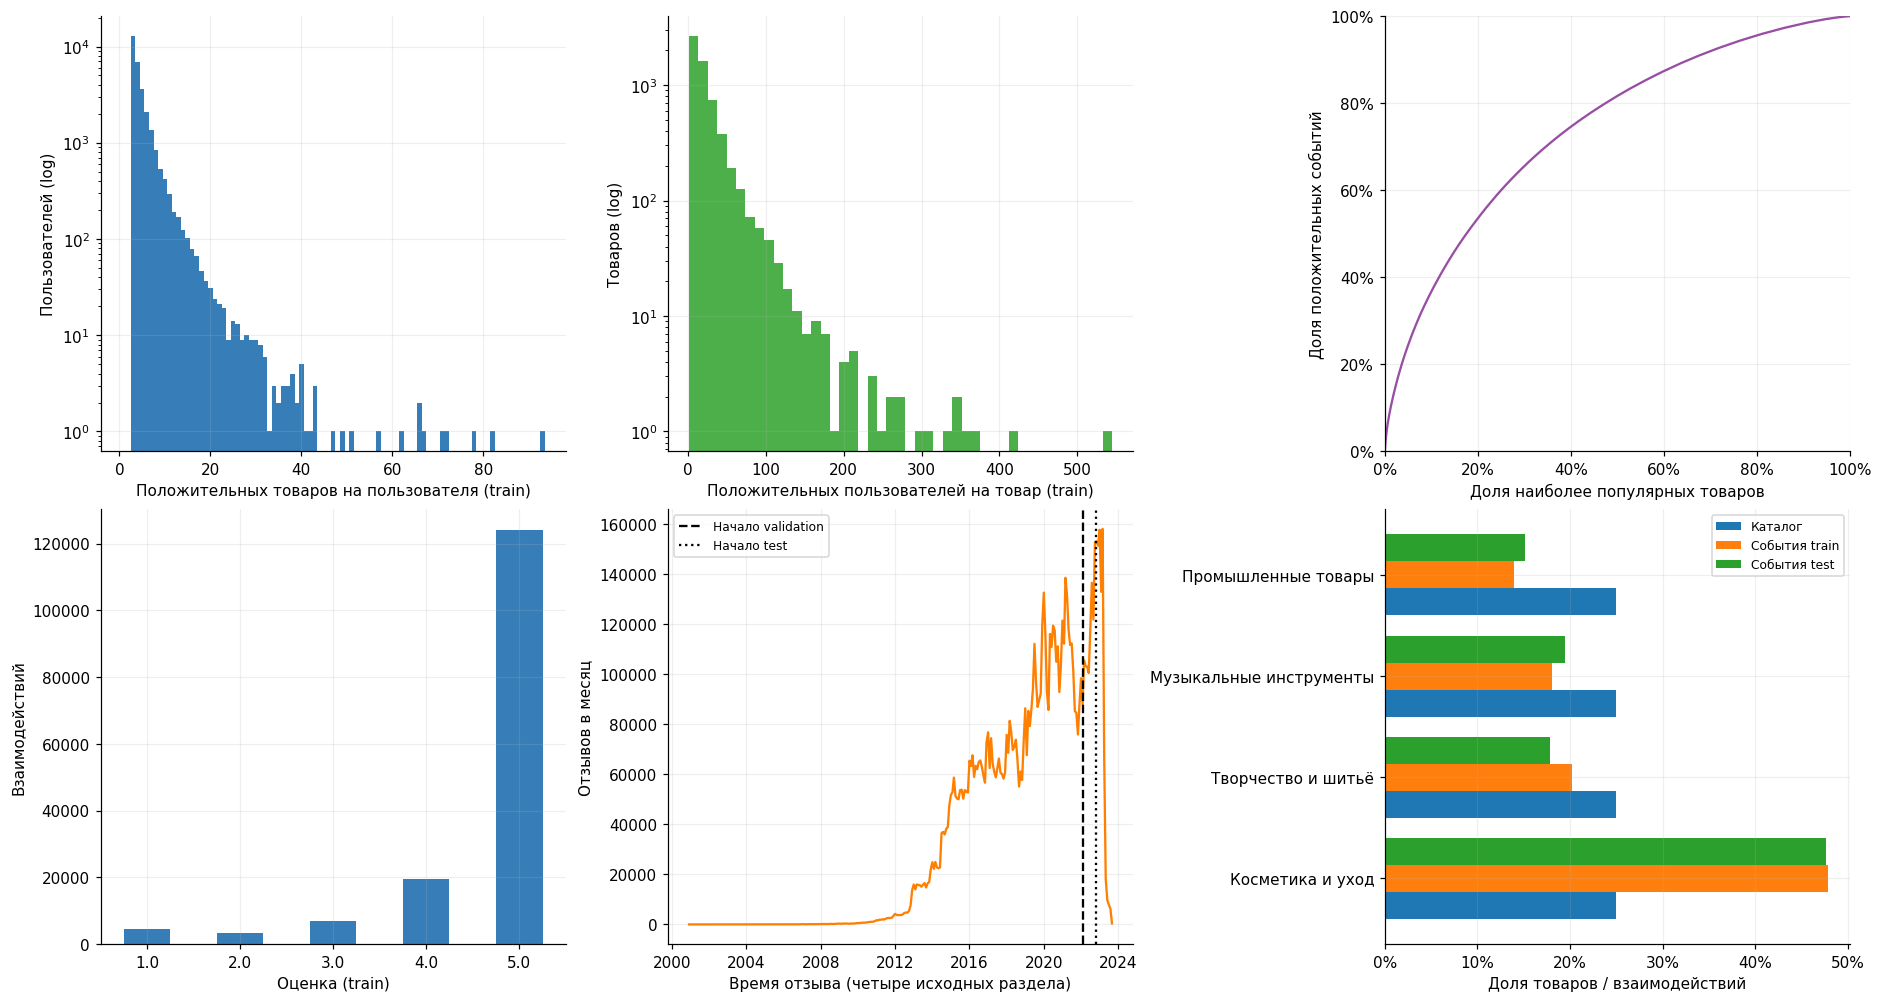

,user_activity,item_popularity
count,30000.000000,5998.000000
mean,4.786167,23.938813
std,3.310429,28.955857
min,3.000000,1.000000
25%,3.000000,9.000000
50%,4.000000,15.000000
75%,5.000000,29.000000
max,93.000000,545.000000


In [5]:
from matplotlib.ticker import PercentFormatter

activity = np.asarray(X_train.sum(axis=1)).ravel()
popularity = np.asarray(X_train.sum(axis=0)).ravel()
domain_labels = dict(zip(CATEGORIES, ["Косметика и уход", "Творчество и шитьё",
                                     "Музыкальные инструменты", "Промышленные товары"]))
fig, axes = plt.subplots(2, 3, figsize=(17, 9), layout="constrained")
axes[0, 0].hist(activity, bins=np.arange(.5, activity.max() + 1.5), color="#377eb8")
axes[0, 0].set(xlabel="Положительных товаров на пользователя (train)", ylabel="Пользователей (log)", yscale="log")
axes[0, 1].hist(popularity, bins=45, color="#4daf4a")
axes[0, 1].set(xlabel="Положительных пользователей на товар (train)", ylabel="Товаров (log)", yscale="log")
sorted_popularity = np.sort(popularity)[::-1]
axes[0, 2].plot(np.arange(len(sorted_popularity) + 1) / len(sorted_popularity),
                np.r_[0, np.cumsum(sorted_popularity) / sorted_popularity.sum()], color="#984ea3")
axes[0, 2].set(xlabel="Доля наиболее популярных товаров", ylabel="Доля положительных событий", xlim=(0, 1), ylim=(0, 1))
for axis in [axes[0, 2].xaxis, axes[0, 2].yaxis]:
    axis.set_major_formatter(PercentFormatter(1))
train.rating.value_counts().sort_index().plot.bar(ax=axes[1, 0], color="#377eb8", rot=0)
axes[1, 0].set(xlabel="Оценка (train)", ylabel="Взаимодействий")
months = pd.to_datetime(clean.timestamp, unit="ms", utc=True).dt.tz_localize(None).dt.to_period("M")
monthly = clean.groupby(months).size()
axes[1, 1].plot(monthly.index.to_timestamp(), monthly.values, color="#ff7f00")
for cutoff, label, style in [(TRAIN_END, "Начало validation", "--"), (VALID_END, "Начало test", ":")]:
    axes[1, 1].axvline(pd.to_datetime(cutoff, unit="ms"), color="black", linestyle=style, label=label)
axes[1, 1].set(xlabel="Время отзыва (четыре исходных раздела)", ylabel="Отзывов в месяц")
axes[1, 1].legend(fontsize=8)
shares = pd.DataFrame({"Каталог": metadata.domain.value_counts(normalize=True),
                       "События train": train.domain.value_counts(normalize=True),
                       "События test": test.domain.value_counts(normalize=True)}).reindex(CATEGORIES)
shares.rename(index=domain_labels).plot.barh(ax=axes[1, 2], width=.8)
axes[1, 2].set(xlabel="Доля товаров / взаимодействий", ylabel="")
axes[1, 2].xaxis.set_major_formatter(PercentFormatter(1))
axes[1, 2].legend(fontsize=8)
plt.show()
display(pd.DataFrame({"user_activity": pd.Series(activity).describe(),
                      "item_popularity": pd.Series(popularity).describe()}))
top_share = sorted_popularity[:max(1, int(.1 * len(sorted_popularity)))].sum() / sorted_popularity.sum()
print(f"Топ-10% товаров: {top_share:.1%} положительных событий train. Последний месяц источника может быть неполным.")


**FM:** ID + раздел, полный путь категории и store: товарная тематика и принадлежность магазину. Редкие пути/store (<5 товаров) объединяем. Словари фиксируем по train-каталогу. Названия нужны для просмотра рекомендаций; агрегаты рейтингов не используются. Карточки — один снимок: доступность неизменных категорий/store в прошлом является предположением.


## 3. Протокол
Границы — 80-й и 90-й процентили времени исходных очищенных данных. Train → validation → test; равные timestamp не разделяем. После отбора доли меняются. Настройки выбираем по validation, перед test переобучаем на train+validation.

Общий train-каталог, исключаем все ранее оценённые товары. Новые ID не оцениваем. Пользователь участвует при ≥1 релевантном товаре и ≥10 кандидатах; потерю покрытия измеряем отдельно.

Основная метрика **NDCG@10** учитывает порядок; **Recall@10** — полноту. Усредняем по пользователям:

$$Recall@10(u)=|R_u\cap L_{u,10}|/|R_u|,$$
$$NDCG@10(u)=\frac{\sum_{k=1}^{10}\mathbf1[L_{u,k}\in R_u]/\log_2(k+1)}{\sum_{k=1}^{\min(10,|R_u|)}1/\log_2(k+1)}.$$

Релевантность всех моделей: будущая оценка ≥4. Дополнительно: Precision, HR, покрытие каталога и время.


In [6]:
valid_relevance, valid_users = make_relevance(valid, seen_train, shape)
print("Общие validation-пользователи:", len(valid_users))
print("Validation-релевантных пар:", valid_relevance[valid_users].nnz)
print("Одинаковый каталог:", shape[1], "товаров; известные исключаются персонально")
assert np.all(np.diff(X_train.tocsc().indptr) > 0)
assert np.all(np.asarray(X_train.sum(axis=1)).ravel() >= 3)


Общие validation-пользователи: 4427
Validation-релевантных пар: 6862
Одинаковый каталог: 5998 товаров; известные исключаются персонально


## 4. Модели и подбор
$H_{ui}=\mathbf1[r_{ui}\ge4]$ — положительная история.

**ItemKNN:** cosine с усадкой $s_{ij}=\frac{H_{:i}^TH_{:j}}{\|H_{:i}\|\|H_{:j}\|}\frac{n_{ij}}{n_{ij}+\gamma}$, диагональ нулевая. Для каждого целевого товара — k сильнейших соседей; score $Hs$. Сетка: k∈{20,80}, γ∈{0,20}.

**iALS:** $p=H$, $c=1+20H$;
$$\min_{X,Y}\sum_{ui}c_{ui}(p_{ui}-x_u^Ty_i)^2+\lambda(\|X\|^2+\|Y\|^2).$$
Чередуем решения $x_u=(Y^TC_uY+\lambda I)^{-1}Y^TC_up_u$ и аналогичные для товаров. Факторы∈{16,32}, λ∈{1,10}, 12 итераций.

**EASE:** $\min_B\|H-HB\|_F^2+\lambda\|B\|_F^2$, diag(B)=0. Для $P=(H^TH+\lambda I)^{-1}$: $B_{ij}=-P_{ij}/P_{jj}$ при i≠j; score HB. λ∈{50,200,1000}.

**FM:** ID + раздел/полный путь/store;
$$s(z)=w^Tz+\tfrac12\sum_f[(\sum_a v_{af}z_a)^2-\sum_a v_{af}^2z_a^2].$$
BPR: $\log(1+e^{-(s^+-s^-)})$ + L2, Adam. Каждый положительный пример за эпоху получает равномерный неизвестный товар; исключаем всё известное в текущей обучающей истории, не читая будущие события. Факторы∈{16,32}, эпохи∈{10,20}; lr=0.005, L2=1e−5, batch=2048. Контроль — FM только с ID; дополнительно сравниваем одинаковые настройки с метаданными и без.

**Собственный ALS:** для наблюдаемой пары
$$\widetilde p_{ui}=\frac{r_{ui}-3}{2}\,2^{-(T-t_{ui})/(86400000h)},$$
иначе 0. Низкие оценки дают отрицательное предпочтение, старые ослабевают; предполагаем изменение интересов со временем. Оптимизация как у iALS, но с новым p. Confidence **тот же**, c=1+20H; правую часть считаем по всем ненулевым таргетам, включая отрицательные. Остальные настройки берём у выбранного iALS; подбираем h∈{365,1095} дней. При refit T переносим на границу validation/test. Test-релевантность не меняется.


In [7]:
grids = {
    "ItemKNN": [{"neighbors": k, "shrinkage": s} for k, s in product([20, 80], [0., 20.])],
    "iALS": [{"factors": f, "regularization": r, "alpha": 20., "iterations": 12, "seed": SEED}
             for f, r in product([16, 32], [1., 10.])],
    "EASE": [{"regularization": r} for r in [50., 200., 1000.]],
    "FM + metadata": [{"factors": f, "epochs": e, "learning_rate": .005,
                       "regularization": 1e-5, "batch_size": 2048, "seed": SEED}
                      for f, e in product([16, 32], [10, 20])],
}
grids["FM IDs"] = [dict(p) for p in grids["FM + metadata"]]
selected, validation_tables = {}, []
for name, grid in grids.items():
    selected[name], trials = search(name, grid, train, shape, metadata_codes, TRAIN_END,
                                    valid_relevance, valid_users, seen_train)
    validation_tables.append(trials)
custom_grid = [{**selected["iALS"], "half_life_days": h} for h in [365., 1095.]]
selected["Custom ALS"], trials = search("Custom ALS", custom_grid, train, shape,
                                       metadata_codes, TRAIN_END, valid_relevance,
                                       valid_users, seen_train)
validation_tables.append(trials)
validation_results = pd.concat(validation_tables, ignore_index=True)
display(validation_results[["model", "parameters", "NDCG@10", "Recall@10"]]
        .sort_values(["model", "NDCG@10"], ascending=[True, False]).round(5))
validation_results.to_csv(ARTIFACTS / "validation.csv", index=False)
_ = (ARTIFACTS / "selected_parameters.json").write_text(json.dumps(selected, indent=2))


ItemKNN: {'neighbors': 20, 'shrinkage': 0.0}; validation NDCG@10=0.01522
ItemKNN: {'neighbors': 20, 'shrinkage': 20.0}; validation NDCG@10=0.02210
ItemKNN: {'neighbors': 80, 'shrinkage': 0.0}; validation NDCG@10=0.01522
ItemKNN: {'neighbors': 80, 'shrinkage': 20.0}; validation NDCG@10=0.02368
iALS: {'factors': 16, 'regularization': 1.0, 'alpha': 20.0, 'iterations': 12, 'seed': 42}; validation NDCG@10=0.02078
iALS: {'factors': 16, 'regularization': 10.0, 'alpha': 20.0, 'iterations': 12, 'seed': 42}; validation NDCG@10=0.02081
iALS: {'factors': 32, 'regularization': 1.0, 'alpha': 20.0, 'iterations': 12, 'seed': 42}; validation NDCG@10=0.02228
iALS: {'factors': 32, 'regularization': 10.0, 'alpha': 20.0, 'iterations': 12, 'seed': 42}; validation NDCG@10=0.02215
EASE: {'regularization': 50.0}; validation NDCG@10=0.02565
EASE: {'regularization': 200.0}; validation NDCG@10=0.02699
EASE: {'regularization': 1000.0}; validation NDCG@10=0.02745
FM + metadata: {'factors': 16, 'epochs': 10, 'learni

,model,parameters,NDCG@10,Recall@10
19,Custom ALS,"{""alpha"": 20.0, ""factors"": 32, ""half_life_days...",0.02727,0.04893
20,Custom ALS,"{""alpha"": 20.0, ""factors"": 32, ""half_life_days...",0.02521,0.04488
10,EASE,"{""regularization"": 1000.0}",0.02745,0.04893
9,EASE,"{""regularization"": 200.0}",0.02699,0.04652
8,EASE,"{""regularization"": 50.0}",0.02565,0.04445
14,FM + metadata,"{""batch_size"": 2048, ""epochs"": 20, ""factors"": ...",0.01701,0.03029
12,FM + metadata,"{""batch_size"": 2048, ""epochs"": 20, ""factors"": ...",0.01643,0.03078
13,FM + metadata,"{""batch_size"": 2048, ""epochs"": 10, ""factors"": ...",0.01601,0.02808
11,FM + metadata,"{""batch_size"": 2048, ""epochs"": 10, ""factors"": ...",0.01495,0.02445
17,FM IDs,"{""batch_size"": 2048, ""epochs"": 10, ""factors"": ...",0.02314,0.03984


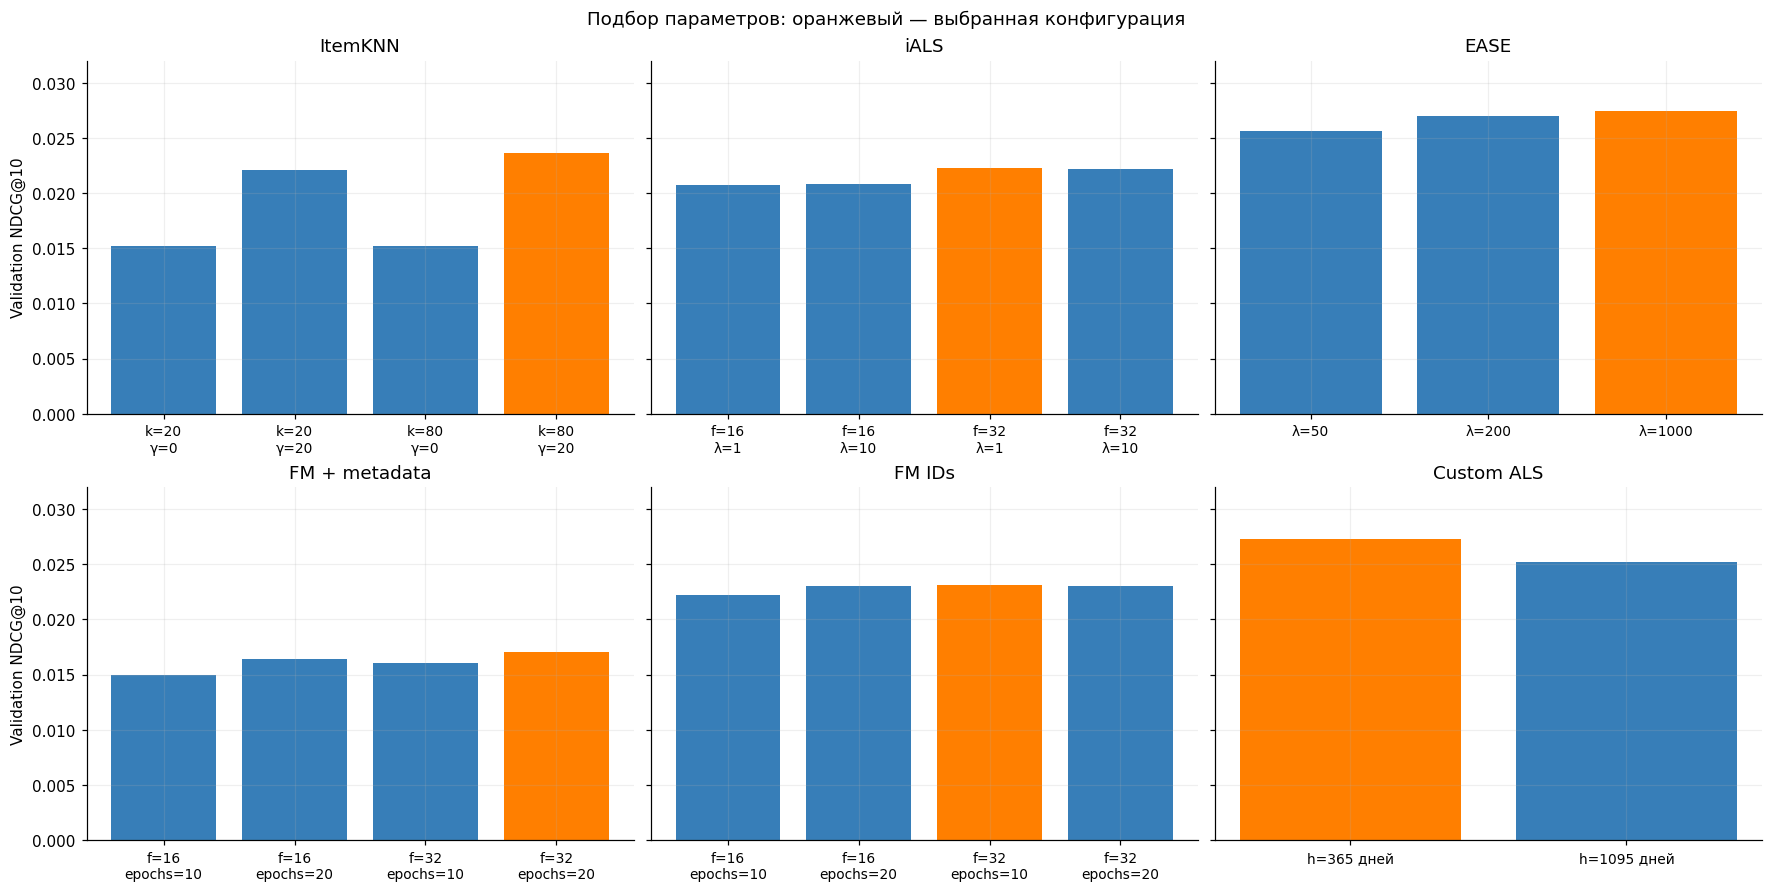

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True, layout="constrained")
for ax, (name, part) in zip(axes.flat, validation_results.groupby("model", sort=False)):
    labels = []
    for value in part.parameters:
        p = json.loads(value)
        if name == "ItemKNN": label = f"k={p['neighbors']}\nγ={p['shrinkage']:g}"
        elif name == "iALS": label = f"f={p['factors']}\nλ={p['regularization']:g}"
        elif name == "EASE": label = f"λ={p['regularization']:g}"
        elif name.startswith("FM"): label = f"f={p['factors']}\nepochs={p['epochs']}"
        else: label = f"h={p['half_life_days']:g} дней"
        labels.append(label)
    values = part["NDCG@10"].to_numpy()
    colors = ["#ff7f00" if j == int(np.argmax(values)) else "#377eb8" for j in range(len(values))]
    ax.bar(np.arange(len(values)), values, color=colors)
    ax.set(xticks=np.arange(len(values)), xticklabels=labels, title=name, ylim=(0, .032))
    ax.tick_params(axis="x", labelsize=9)
for ax in axes[:, 0]: ax.set_ylabel("Validation NDCG@10")
fig.suptitle("Подбор параметров: оранжевый — выбранная конфигурация")
plt.show()


Выбираем максимум validation NDCG@10 (при равенстве — первую конфигурацию). Контроль FM: одинаковые настройки, инициализация общих ID и негативные примеры, с метаданными и без.


In [9]:
final_settings = {"Popularity": {}, **selected}
fm_matched = dict(selected["FM + metadata"])
display(pd.DataFrame([{"model": name, "selected_parameters": json.dumps(p, sort_keys=True)}
                      for name, p in final_settings.items()]))
experiment_config = {
    "dataset": DATASET, "revision": REVISION, "seed": SEED,
    "train_end_ms": TRAIN_END, "valid_end_ms": VALID_END,
    "time_quantiles": [.8, .9], "quantile_interpolation": "higher",
    "cutoff_source": "all cleaned category events before user/item selection",
    "sample_max_users": MAX_USERS, "sample_max_items": MAX_ITEMS,
    "source_core": 5, "categories": list(CATEGORIES), "min_train_item_users": 2,
    "catalog_selection": "equal department quotas",
    "user_selection": "department reservation then seeded uniform fill",
    "main_metric": "NDCG@10", "k": 10,
    "selection": "balanced train-only catalog; department-reserved then uniform training-active users",
    "activity_days": 730, "min_user_positive_items": 3,
    "selected": final_settings, "fm_matched_parameters": fm_matched,
    "grids": {**grids, "Custom ALS": custom_grid}, "versions": versions,
    "source_sha256": {name: file_hash(Path(DATA_DIRECTORY) / name) for name in FILES},
}
_ = (ARTIFACTS / "experiment_manifest.json").write_text(json.dumps(experiment_config, indent=2))


,model,selected_parameters
0,Popularity,{}
1,ItemKNN,"{""neighbors"": 80, ""shrinkage"": 20.0}"
2,iALS,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 1..."
3,EASE,"{""regularization"": 1000.0}"
4,FM + metadata,"{""batch_size"": 2048, ""epochs"": 20, ""factors"": ..."
5,FM IDs,"{""batch_size"": 2048, ""epochs"": 10, ""factors"": ..."
6,Custom ALS,"{""alpha"": 20.0, ""factors"": 32, ""half_life_days..."


## 5. Test
Refit на train+validation; общий каталог и пользователи, обновлённая история известных товаров.


In [ ]:
final_history = pd.concat([train, valid], ignore_index=True)
seen_final = interaction_matrix(final_history, shape, positive_only=False)
test_relevance, test_users = make_relevance(test, seen_final, shape)

coverage_rows = []
for name, start, end in [("Validation", TRAIN_END, VALID_END),
                         ("Test", VALID_END, float("inf"))]:
    target = clean[(clean.timestamp >= start) & (clean.timestamp < end) & (clean.rating >= 4)]
    warm_users = target[target.user_id.isin(user_ids)]
    warm_catalog = warm_users[warm_users.parent_asin.isin(item_ids)]
    coverage_rows.append({"period": name, "all_positive_pairs": len(target),
                          "selected_user_positive_pairs": len(warm_users),
                          "in_selected_catalog": len(warm_catalog),
                          "catalog_coverage_for_selected_users":
                              len(warm_catalog) / max(1, len(warm_users)),
                          "users_outside_training_sample": target.loc[
                              ~target.user_id.isin(user_ids), "user_id"].nunique()})
display(pd.DataFrame(coverage_rows))
print("Test: общих пользователей", len(test_users), "| релевантных пар",
      test_relevance[test_users].nnz, "| каталог", shape[1])

final_models, test_details, rows = {}, {}, []
for name, parameters in final_settings.items():
    print("Final fit:", name, flush=True)
    model = fit_model(name, parameters, final_history, shape, metadata_codes, VALID_END)
    metrics, details = evaluate(model, test_relevance, test_users, seen_final)
    final_models[name], test_details[name] = model, details
    rows.append({"model": name, "parameters": json.dumps(parameters, sort_keys=True),
                 "fit_seconds": model.fit_seconds, **metrics})


matched_name = ("FM IDs" if fm_matched == selected["FM IDs"]
                else "FM IDs (matched settings)")
if matched_name not in final_models:
    model = fit_model("FM IDs", fm_matched, final_history, shape, metadata_codes, VALID_END)
    metrics, details = evaluate(model, test_relevance, test_users, seen_final)
    final_models[matched_name], test_details[matched_name] = model, details
    rows.append({"model": matched_name, "parameters": json.dumps(fm_matched, sort_keys=True),
                 "fit_seconds": model.fit_seconds, **metrics})
comparison = pd.DataFrame(rows).set_index("model")
assert (comparison[["eval_users", "candidate_items", "relevant_pairs"]].nunique() == 1).all()
display(comparison[["NDCG@10", "Recall@10", "Precision@10", "HR@10", "coverage",
                    "fit_seconds", "parameters"]].sort_values("NDCG@10", ascending=False).round(5))
comparison.to_csv(ARTIFACTS / "test_comparison.csv")
for name, details in test_details.items():
    details.to_csv(ARTIFACTS / (name.replace(" ", "_").replace("+", "and") + "_per_user.csv"), index=False)

reference_users = test_details["Popularity"].user_idx.to_numpy()
for name, detail in test_details.items():
    assert np.array_equal(detail.user_idx.to_numpy(), reference_users)
    assert detail.user_idx.is_unique and (detail.relevant_items >= 1).all()
    for metric in ["Recall@10", "NDCG@10", "Precision@10", "HR@10"]:
        assert detail[metric].between(0, 1).all()
        np.testing.assert_allclose(detail[metric].mean(), comparison.loc[name, metric])
    assert detail.relevant_items.sum() == comparison.loc[name, "relevant_pairs"]
    np.testing.assert_array_less(detail["Precision@10"] * 10, detail.relevant_items + 1e-8)
    probe = test_users[:32]
    ranking = final_models[name].recommend(probe, seen_final, 10)
    assert ranking.shape == (len(probe), 10)
    assert all(len(set(row)) == 10 for row in ranking)
    assert not np.asarray(seen_final[np.repeat(probe, 10), ranking.ravel()]).any()
for name, parameters in selected.items():
    trials = validation_results[validation_results.model == name]
    assert parameters == json.loads(trials.loc[trials["NDCG@10"].idxmax(), "parameters"])
print("Sanity checks: единые пользователи, метрики, top-10, исключение известных, выбор по validation — OK")


Test: общих пользователей 2471 | релевантных пар 3576 | каталог 5998
Final fit: Popularity
Final fit: ItemKNN
Final fit: iALS
Final fit: EASE
Final fit: FM + metadata
Final fit: FM IDs
Final fit: Custom ALS
Sanity checks: единые пользователи, метрики, top-10, исключение известных, выбор по validation — OK


,period,all_positive_pairs,selected_user_positive_pairs,in_selected_catalog,catalog_coverage_for_selected_users,users_outside_training_sample
0,Validation,728031,44612,6862,0.153815,245449
1,Test,767605,26594,3576,0.134466,193112


,NDCG@10,Recall@10,Precision@10,HR@10,coverage,fit_seconds,parameters
model,,,,,,,
EASE,0.02237,0.04027,0.00599,0.05787,0.41247,3.74644,"{""regularization"": 1000.0}"
Custom ALS,0.02221,0.03999,0.00571,0.05382,0.15572,27.12646,"{""alpha"": 20.0, ""factors"": 32, ""half_life_days..."
FM IDs (matched settings),0.02152,0.03628,0.00534,0.05261,0.04752,7.19602,"{""batch_size"": 2048, ""epochs"": 20, ""factors"": ..."
iALS,0.02127,0.03913,0.00591,0.05463,0.14421,26.91988,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 1..."
FM IDs,0.02027,0.03614,0.00538,0.05221,0.04268,3.93270,"{""batch_size"": 2048, ""epochs"": 10, ""factors"": ..."
ItemKNN,0.01756,0.03104,0.00449,0.04371,0.65288,1.83853,"{""neighbors"": 80, ""shrinkage"": 20.0}"
FM + metadata,0.01429,0.02915,0.00405,0.04006,0.05835,9.81707,"{""batch_size"": 2048, ""epochs"": 20, ""factors"": ..."
Popularity,0.00997,0.01654,0.00255,0.02550,0.00233,0.00127,{}


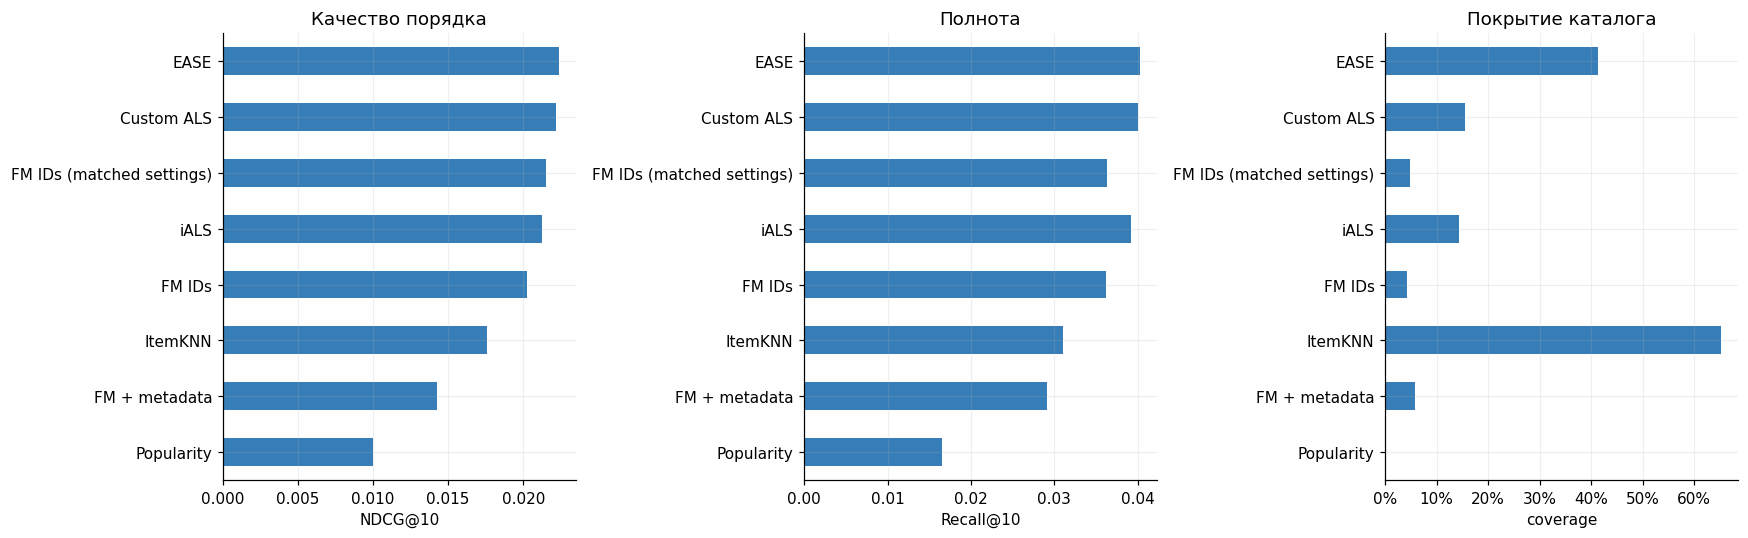

,comparison,delta_NDCG@10,ci_low,ci_high
0,Custom ALS minus iALS,0.000934,-0.003284,0.005249
1,FM + metadata minus FM IDs (matched settings),-0.007231,-0.011200,-0.003261
2,Custom ALS minus FM IDs,0.001936,-0.002865,0.006656
3,FM + metadata minus FM IDs,-0.005982,-0.010007,-0.001795


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
order = comparison.sort_values("NDCG@10").index
for ax, metric, title in zip(axes, ["NDCG@10", "Recall@10", "coverage"],
                              ["Качество порядка", "Полнота", "Покрытие каталога"]):
    comparison.loc[order, metric].plot.barh(ax=ax, color="#377eb8")
    ax.set(xlabel=metric, ylabel="", title=title)
    if metric == "coverage": ax.xaxis.set_major_formatter(PercentFormatter(1))
fig.tight_layout()
plt.show()

ablation_pairs = [("Custom ALS", "iALS"), ("FM + metadata", matched_name),
                  ("Custom ALS", "FM IDs")]
if matched_name != "FM IDs":
    ablation_pairs.append(("FM + metadata", "FM IDs"))
ablation_rows = [{"comparison": f"{left} minus {right}",
                  **paired_interval(test_details[left], test_details[right])}
                 for left, right in ablation_pairs]
ablations = pd.DataFrame(ablation_rows)
display(ablations.round(6))
ablations.to_csv(ARTIFACTS / "ablations.csv", index=False)


Парный bootstrap по пользователям: 2000 повторов, 95% CI, seed=42. Интервал с нулём не подтверждает преимущество. Один split; случайность обучения и множественные сравнения не учтены.


In [ ]:

segment_rows = []
for name, detail in test_details.items():
    part = detail.copy()
    part["train_activity_group"] = pd.cut(activity[part.user_idx],
        bins=[-np.inf, 3, 5, np.inf], labels=["3 товара", "4–5 товаров", "6+ товаров"])
    grouped = part.groupby("train_activity_group", observed=True)["NDCG@10"].agg(["mean", "size"]).reset_index()
    grouped["model"] = name
    segment_rows.append(grouped)
segments = pd.concat(segment_rows)
display(segments.pivot(index="model", columns="train_activity_group", values="mean").round(5))
display(segments.pivot(index="model", columns="train_activity_group", values="size"))


train_activity_group,3 товара,4–5 товаров,6+ товаров
model,,,
Custom ALS,0.02315,0.02198,0.02151
EASE,0.02114,0.02168,0.02420
FM + metadata,0.01464,0.01724,0.01122
FM IDs,0.01668,0.02185,0.02225
FM IDs (matched settings),0.01665,0.02422,0.02368
ItemKNN,0.01515,0.01856,0.01895
Popularity,0.01058,0.01033,0.00906
iALS,0.01356,0.02372,0.02640


train_activity_group,3 товара,4–5 товаров,6+ товаров
model,,,
Custom ALS,822,793,856
EASE,822,793,856
FM + metadata,822,793,856
FM IDs,822,793,856
FM IDs (matched settings),822,793,856
ItemKNN,822,793,856
Popularity,822,793,856
iALS,822,793,856


**Пример:** можно посмотреть по тест юзерам историю и рекомендации 


In [ ]:
profiles = train.groupby("user_idx").agg(domains=("domain", "nunique"), history_size=("item_idx", "size"))
example_user = int(profiles.reindex(test_users).sort_values(
    ["domains", "history_size"], ascending=[False, False], kind="stable").index[0])
positive_history = interaction_matrix(final_history, shape)
example_history = final_history[final_history.user_idx == example_user].merge(
    metadata, on="parent_asin", how="left")
display(example_history[["parent_asin", "title", "domain_x", "rating", "timestamp"]].rename(
    columns={"domain_x": "domain"}).tail(15))
recommendation_rows = []
for name in ["ItemKNN", "iALS", "EASE", "FM + metadata", "Custom ALS"]:
    top = final_models[name].recommend([example_user], seen_final, 10)[0]
    for rank, item in enumerate(top, start=1):
        recommendation_rows.append({"model": name, "rank": rank,
            "parent_asin": item_ids[item], "title": metadata.iloc[item].title,
            "domain": metadata.iloc[item].domain, "category": metadata.iloc[item].category,
            "relevant_in_test": bool(test_relevance[example_user, item])})
display(pd.DataFrame(recommendation_rows))
top_ease = final_models["EASE"].recommend([example_user], seen_final, 10)[0, 0]
sources = positive_history[example_user].indices
contributions = final_models["EASE"].weights[sources, top_ease]
explanation = metadata.iloc[sources][["title", "parent_asin"]].copy()
explanation["contribution"] = contributions
print("EASE: целевой товар:", metadata.iloc[top_ease].title)
display(explanation.reindex(explanation.contribution.abs().sort_values(ascending=False).index).head(10))
np.testing.assert_allclose(contributions.sum(), final_models["EASE"].score([example_user])[0, top_ease])


EASE: целевой товар: Maybelline New York Fit Me Matte + Poreless Liquid Foundation, Pouch Format, 102 Fair Porcelain, 1.3 Ounce


,parent_asin,title,domain,rating,timestamp
82,B0B1BC86MY,"Clean Revolution Foaming Hand Soap | Gentle, M...",Beauty_and_Personal_Care,5.0,1602699007723
83,B08MHMN8TB,L'Oreal Paris Le Color Gloss One Step In-Showe...,Beauty_and_Personal_Care,5.0,1606340629679
84,B0BVLJTMV2,REGIS Kalimba 17-Key Thumb Piano with Instruct...,Musical_Instruments,5.0,1607388274562
85,B0BNDXH22P,Fiora Naturals Hair Detangling Brush -100% Bio...,Beauty_and_Personal_Care,5.0,1607389265091
86,B0B18ZYNL1,"Liquid Lipstick By Revlon, Lip Makeup, ColorSt...",Beauty_and_Personal_Care,4.0,1608234679695
87,B08LFKMKVK,Ethereal Nature 99% Natural Hair Oil Blend Jam...,Beauty_and_Personal_Care,4.0,1608404823304
88,B0C3CJ8ZN3,Bekind Apex 2-in-1 Hair Straightener Flat Iron...,Beauty_and_Personal_Care,5.0,1610333680287
89,B0BYPG9KM1,Candy Lover Jelly Gel Nail Polish Kit with 36W...,Beauty_and_Personal_Care,5.0,1615438400016
90,B0B21DCTR5,Modelones 11 Pcs Dip Powder Nail Kit Starter 4...,Beauty_and_Personal_Care,5.0,1617844034214
91,B09NFFSC5M,Schmidt's Aluminum Free Natural Deodorant for ...,Beauty_and_Personal_Care,5.0,1619800770962


,model,rank,parent_asin,title,domain,category,relevant_in_test
0,ItemKNN,1,B09ZKMD1VS,Maybelline New York Fit Me Matte + Poreless Li...,Beauty_and_Personal_Care,Beauty_and_Personal_Care > Beauty & Personal C...,False
1,ItemKNN,2,B0849FH9MC,Sally Hansen - Good. Kind. Pure Vegan Nail Pol...,Beauty_and_Personal_Care,Beauty_and_Personal_Care > Beauty & Personal C...,False
2,ItemKNN,3,B0BM3JMJYL,HAUS LABORATORIES by Lady Gaga: LE MONSTER MAT...,Beauty_and_Personal_Care,Beauty_and_Personal_Care > Beauty & Personal C...,False
3,ItemKNN,4,B08YG7KV61,Chapstick Party Favor Lip Balm Gift Pack Toast...,Beauty_and_Personal_Care,Beauty_and_Personal_Care > Beauty & Personal C...,False
4,ItemKNN,5,B08CSJ1XZ5,"EZbobble 18PCS Spiral Hair Ties No Crease, Coi...",Beauty_and_Personal_Care,Beauty_and_Personal_Care > Beauty & Personal C...,False
5,ItemKNN,6,B093BXMMCD,"Liquid Foundation by Revlon, Age Defying 3XFac...",Beauty_and_Personal_Care,Beauty_and_Personal_Care > Beauty & Personal C...,False
6,ItemKNN,7,B08BZ9GNF5,L'Oréal Paris True Match Eye Cream in a Concea...,Beauty_and_Personal_Care,Beauty_and_Personal_Care > Beauty & Personal C...,False
7,ItemKNN,8,B0B6MTYFBL,Covergirl Outlast Extreme Wear 3-in-1 Full Cov...,Beauty_and_Personal_Care,Beauty_and_Personal_Care > Beauty & Personal C...,False
8,ItemKNN,9,B09V65YL5Y,Reusable Multilayer Fabric Face Mask in Prints...,Arts_Crafts_and_Sewing,"Arts_Crafts_and_Sewing > Arts, Crafts & Sewing...",False
9,ItemKNN,10,B082TRGNMY,EZbobble 12PCS Spiral Hair Ties No Crease，Coil...,Beauty_and_Personal_Care,Beauty_and_Personal_Care > Beauty & Personal C...,False


,title,parent_asin,contribution
2925,"COVERGIRL Clean Fresh Hydrating Concealer, Lig...",B08D8BL3X8,0.027045
5251,"REVLON Super Lustrous Glass Shine Lipstick, Fl...",B0BSZDMYZJ,0.023516
2786,HAUS LABORATORIES By Lady Gaga: RIP LIP LINER ...,B0897FG8S9,0.013392
4396,"Liquid Lipstick By Revlon, Lip Makeup, ColorSt...",B0B18ZYNL1,0.012994
3176,L'Oreal Paris Le Color Gloss One Step In-Showe...,B08MHMN8TB,0.012092
4747,"Dermablend Cover Care Concealer, Full Coverage...",B0BCCD26Z9,0.009618
5353,REVLON Super Lustrous The Luscious Mattes Lips...,B0BW4NMJBK,0.009227
5514,"Pre de Provence Artisanal Soap Bar, Natural Fr...",B0BZX4QM2X,0.007513
3179,"Rimmel Stay Glossy Lip Gloss, Halo-There, 0.18...",B08MMRR8LF,0.004888
1139,ChapStick Classic Collection Flavored Lip Balm...,B0792NT1RS,0.004786


## 6. Выводы


По NDCG@10 лучший результат у **EASE**: **0,02237**, Recall@10 — **0,04027**, λ=1000. Линейная модель совместных взаимодействий оказалась эффективнее более сложных моделей на этой разреженной выборке. Возможная причина — регуляризация и использование связей между товарами без необходимости оценивать много пользовательских параметров. Popularity заметно слабее: NDCG@10=0,00997; почти одинаковые рекомендации всем пользователям охватывают только 0,23% каталога.

**ItemKNN** охватывает больше товаров — 65,3% против 41,2% у EASE, но уступает по NDCG@10 (0,01756). Локальные связи позволяют выдавать разные товары разным пользователям, однако широкое покрытие не гарантирует точных попаданий.

**Custom ALS** близок к EASE: NDCG@10=0,02221 против 0,02127 у iALS. Разность с iALS составляет +0,00093, 95% CI [−0,00328; +0,00525], поэтому преимущество кастомного сигнала не подтверждается. В данных преобладают высокие оценки: новый таргет часто сохраняет положительный знак исходного сигнала, а ослабление старых событий не обязательно улучшает прогноз будущего отзыва.

**FM с метаданными** уступает FM только с ID при одинаковых настройках: NDCG@10=0,01429 против 0,02152 (−33,6%; 95% CI разности [−0,01120; −0,00326]). Раздел, категория и store объединяют товары, но не описывают индивидуальные предпочтения достаточно подробно. Возможно, общие признаки усиливают популярные группы и мешают более точным связям по ID; это объяснение поведения, а не установленная причина.

**Ограничения данных.** Несмотря на почти равные доли товаров четырёх разделов, около 48% train-взаимодействий относятся к косметике и уходу. Поэтому рекомендации часто сосредоточены на этом разделе. Преобладание оценок 5 создаёт перекос к положительной обратной связи: отзывы не отражают все покупки, а отсутствие оценки не означает отсутствие интереса. 5-core и отбор недавно активных пользователей также смещают аудиторию.

Матрица положительных train-взаимодействий разрежена на 99,92%: на пользователя приходится в среднем около 4,8 положительного товара. В test участвует 2471 пользователь, у 75,1% — только один релевантный товар. Ограниченный каталог сохраняет 13,4% будущих положительных оценок выбранных пользователей, поэтому результаты относятся именно к этому каталогу. Один временной split и seed, а также единый снимок карточек ограничивают обобщение результатов; близкие метрики лидеров не доказывают превосходство одного метода.
